n=3500, xbar=3.509451, mu0=3.5, sigma2=2.076548, tau2=1.0
BF10 = 0.0262533, logBF = -3.639965


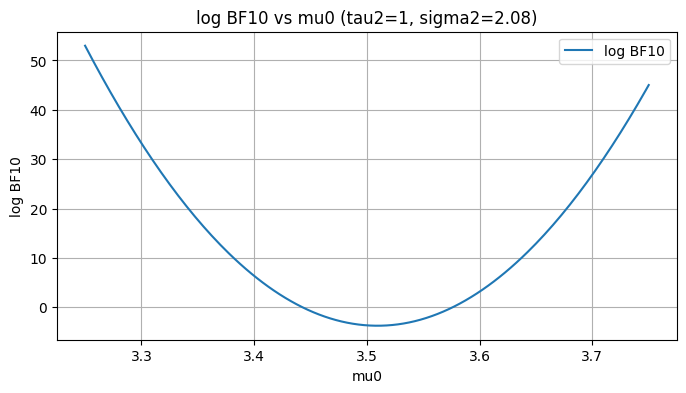

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv('Netflix_Engagement_Dataset.csv')
x = df["Daily Watch Time (Hours)"].dropna().values
n = len(x)
xbar = np.mean(x)


def bayes_factor_normal_known_sigma(xbar, n, mu0, sigma2, tau2):

    var0 = sigma2 / n                        # Var under H0 for xbar
    var1 = sigma2 / n + tau2                 # Var under H1 for xbar

    # log-BF (numerically stable)
    logBF = 0.5 * (np.log(var0) - np.log(var1))
            - 0.5 * (xbar - mu0)**2 * (1.0/var1 - 1.0/var0)

    # convert safely to BF
    if logBF > 700:        # avoid overflow
        BF = np.exp(700)
    elif logBF < -700:
        BF = 0.0
    else:
        BF = float(np.exp(logBF))

    return BF, float(logBF)


sigma2_default = np.var(x, ddof=0)   # population variance estimate
tau2_default = 1.0                   # prior variance for mu under H1 (tweak as needed)


mu0 = 3.5
BF10, logBF = bayes_factor_normal_known_sigma(xbar, n, mu0, sigma2_default, tau2_default)
print(f"n={n}, xbar={xbar:.6f}, mu0={mu0}, sigma2={sigma2_default:.6f}, tau2={tau2_default}")
print(f"BF10 = {BF10:.6g}, logBF = {logBF:.6f}")


mu0_grid = np.linspace(3.25, 3.75, 201)   # adjust range as you like
BFs = []
logBFs = []
for m in mu0_grid:
    bf, lb = bayes_factor_normal_known_sigma(xbar, n, m, sigma2_default, tau2_default)
    BFs.append(bf)
    logBFs.append(lb)

# plot (BF on log scale)
plt.figure(figsize=(8,4))
plt.plot(mu0_grid, logBFs, label='log BF10')

plt.xlabel('mu0')
plt.ylabel('log BF10')
plt.title('log BF10 vs mu0 (tau2={:.2g}, sigma2={:.3g})'.format(tau2_default, sigma2_default))
plt.legend()
plt.grid(True)
plt.show()



=== Metropolis Sampling for Mean Daily Watch Time (Burn-in applied) ===
Samples kept after burn-in: 5000


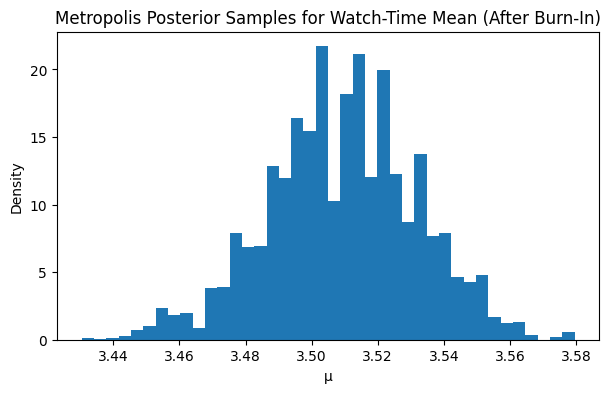

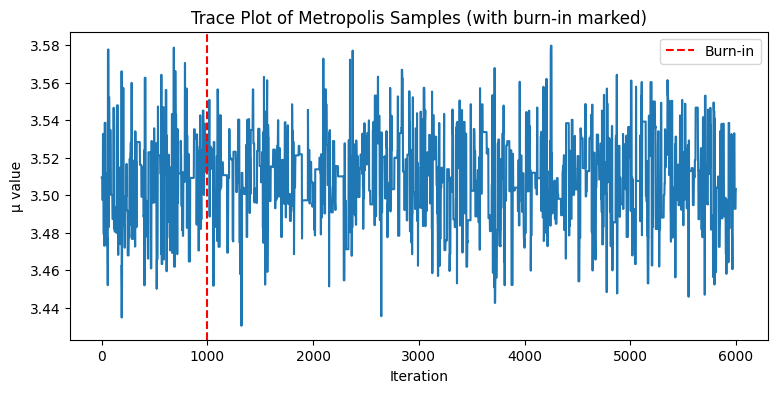

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def mh_mean_estimation(data, iterations=6000, proposal_std=0.2, burn_in=1000):

    x = data.values
    sigma = np.std(x)  # treat as known

    def log_likelihood(mu):
        return -0.5 * np.sum((x - mu)**2) / sigma**2

    samples = []
    mu_curr = np.mean(x)

    for _ in range(iterations):
        mu_prop = np.random.normal(mu_curr, proposal_std)

        logA = log_likelihood(mu_prop) - log_likelihood(mu_curr)
        if np.log(np.random.rand()) < logA:
            mu_curr = mu_prop

        samples.append(mu_curr)

    samples = np.array(samples)

    # --- Burn-in removal ---
    if burn_in >= len(samples):
        raise ValueError("Burn-in period is larger than total iterations!")
    samples_after_burnin = samples[burn_in:]

    return samples_after_burnin, samples


# Run MH on watch time data
watch_data = df["Daily Watch Time (Hours)"].dropna()
mh_samples, raw_samples = mh_mean_estimation(watch_data, iterations=6000, burn_in=1000)

print("\n=== Metropolis Sampling for Mean Daily Watch Time (Burn-in applied) ===")

print(f"Samples kept after burn-in: {len(mh_samples)}")

plt.figure(figsize=(7,4))
plt.hist(mh_samples, bins=40, density=True)
plt.title("Metropolis Posterior Samples for Watch-Time Mean (After Burn-In)")
plt.xlabel("μ")
plt.ylabel("Density")
plt.show()

# Optional: trace plot to visualize convergence
plt.figure(figsize=(9,4))
plt.plot(raw_samples)
plt.axvline(1000, color='red', linestyle='--', label='Burn-in')
plt.title("Trace Plot of Metropolis Samples (with burn-in marked)")
plt.xlabel("Iteration")
plt.ylabel("μ value")
plt.legend()
plt.show()



=== Posterior Estimates (Mean of Samples) ===
beta0 (intercept): 6.7902
beta1 (slope):     0.0465
sigma^2:           7.1322
Samples after burn-in + thinning: 11800


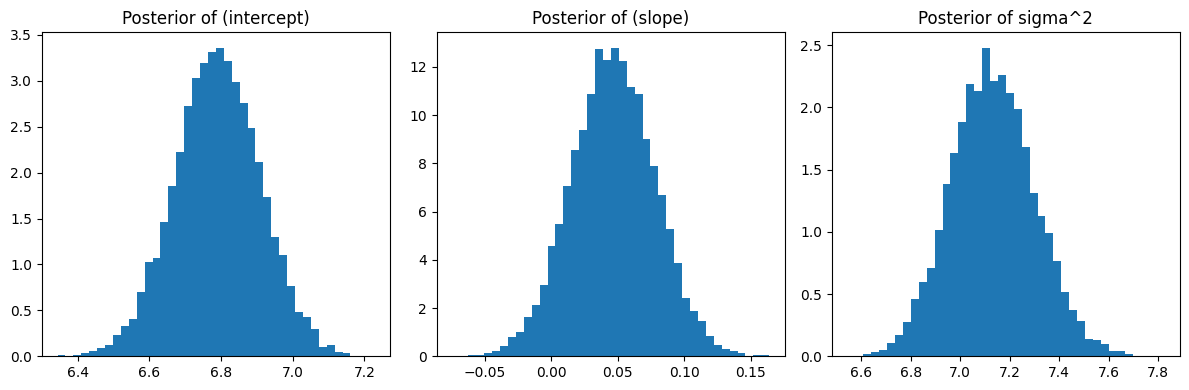

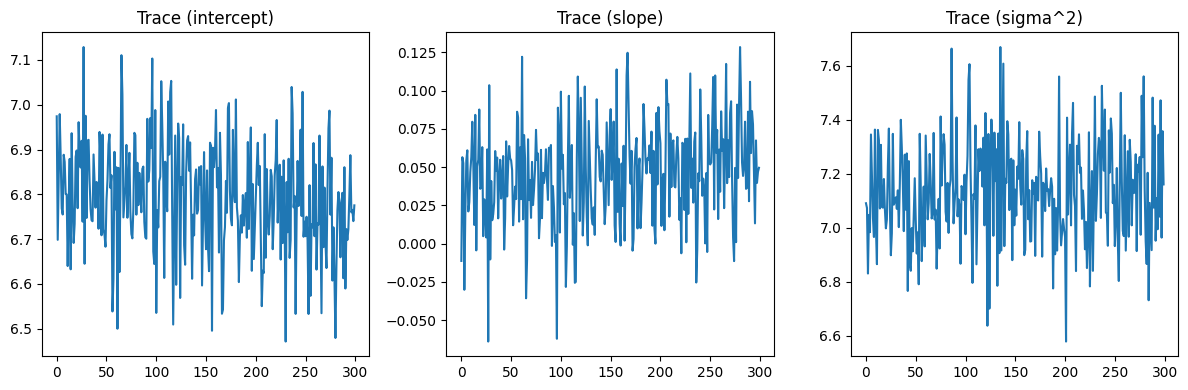

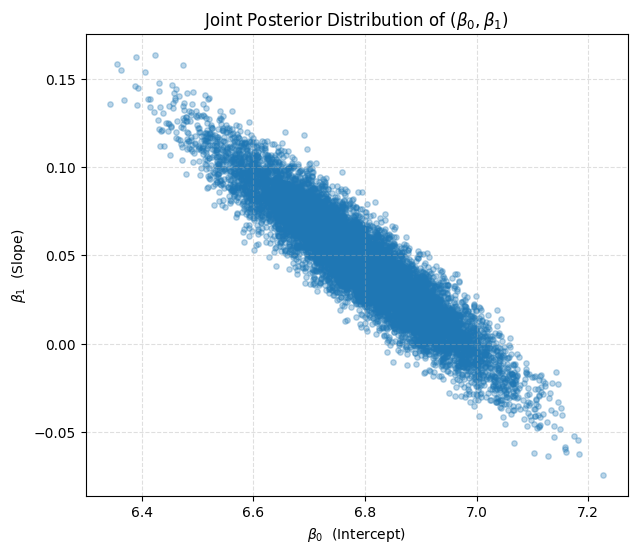

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("Netflix_Engagement_Dataset.csv")

X = df["Daily Watch Time (Hours)"].values
Y = df["Engagement Rate (1-10)"].values

# Add intercept term for beta0
n = len(X)
X_design = np.column_stack((np.ones(n), X))  # column 0: intercept, column 1: slope




def gibbs_linear_regression(Y, X, iterations=60000, burn_in=1000, thin=5):
    n, p = X.shape  # p = 2 (beta0, beta1)


    m0 = np.array([0, 0])        # prior mean of beta
    S0 = np.diag([10, 10]) # prior covariance (broad Normal priors)

    a0 = 2.0                     # inverse-gamma prior shape
    b0 = 1.0                     # inverse-gamma prior scale

    beta_samples = np.zeros((iterations, p))
    sigma2_samples = np.zeros(iterations)

    beta = np.zeros(p)
    sigma2 = 1.0


    XtX = X.T @ X
    XtY = X.T @ Y

    for t in range(iterations):

        S_n = np.linalg.inv(np.linalg.inv(S0) + XtX / sigma2)
        m_n = S_n @ (np.linalg.inv(S0) @ m0 + XtY / sigma2)

        beta = np.random.multivariate_normal(m_n, S_n)


        residuals = Y - X @ beta
        a_n = a0 + n/2
        b_n = b0 + 0.5 * np.sum(residuals**2)

        sigma2 = 1 / np.random.gamma(a_n, 1/b_n)  # Inverse-Gamma

        # Save samples
        beta_samples[t] = beta
        sigma2_samples[t] = sigma2


    beta_samples = beta_samples[burn_in:]
    sigma2_samples = sigma2_samples[burn_in:]

    beta_samples = beta_samples[::thin]
    sigma2_samples = sigma2_samples[::thin]

    return beta_samples, sigma2_samples


# Run Gibbs sampling
beta_samples, sigma2_samples = gibbs_linear_regression(
    Y, X_design, iterations=60000, burn_in=1000, thin=5
)

# Extract
beta0_samples = beta_samples[:, 0]
beta1_samples = beta_samples[:, 1]



print("\n=== Posterior Estimates (Mean of Samples) ===")
print(f"beta0 (intercept): {np.mean(beta0_samples):.4f}")
print(f"beta1 (slope):     {np.mean(beta1_samples):.4f}")
print(f"sigma^2:           {np.mean(sigma2_samples):.4f}")
print(f"Samples after burn-in + thinning: {len(beta0_samples)}")



plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.hist(beta0_samples, bins=40, density=True)
plt.title("Posterior of (intercept)")

plt.subplot(1,3,2)
plt.hist(beta1_samples, bins=40, density=True)
plt.title("Posterior of (slope)")

plt.subplot(1,3,3)
plt.hist(sigma2_samples, bins=40, density=True)
plt.title("Posterior of sigma^2")

plt.tight_layout()
plt.show()


# Trace plots for convergence check
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.plot(beta0_samples[:300])
plt.title("Trace (intercept)")

plt.subplot(1,3,2)
plt.plot(beta1_samples[:300])
plt.title("Trace (slope)")

plt.subplot(1,3,3)
plt.plot(sigma2_samples[:300])
plt.title("Trace (sigma^2)")

plt.tight_layout()
plt.show()


plt.figure(figsize=(7,6))

# Scatter of posterior samples
plt.scatter(beta0_samples, beta1_samples, alpha=0.3, s=15)

plt.xlabel(r"$\beta_0$  (Intercept)")
plt.ylabel(r"$\beta_1$  (Slope)")
plt.title("Joint Posterior Distribution of $(\\beta_0, \\beta_1)$")

plt.grid(True, linestyle='--', alpha=0.4)
plt.show()


